# SecondLook | 07 Letter Audit: Faithfulness and Tone

**Goal:** an independent check that every claim in a letter matches the model's real reasons, plus a tone score from three NLP methods, shown as badges next to each letter in the app.

**Why another check?** The guardrails in notebook 05 check *which factor codes* a letter says it cites and scan for banned words. They cannot see a sentence that cites the right code but says something else. In Phase 1 a live letter called a car the applicant already owns "the car you plan to buy", and only reading the letters caught it. This audit reads the **finished text**.

```
letter ─► Claude (sees ONLY the letter) ─► claims {factor, value, direction}
                                              │
fact sheet (SHAP) ─────────────────────────► match in Python ─► supported / unsupported + reason
letter ─► VADER · TextBlob · Claude rubric ─► tone scores
```

| Score | Meaning |
|---|---|
| **Faithfulness** | supported claims ÷ all claims. A claim is supported when its factor is in the fact sheet, its direction matches the SHAP sign, and any number it quotes matches the fact sheet |
| **Coverage** | share of the top 3 risk factors the letter mentions (not for approvals) |
| **Tone** | VADER compound (−1 to 1), TextBlob polarity (−1 to 1) and subjectivity (0 to 1), and a Claude Haiku 5.5 rubric: respectful, clear, empathetic (1 to 5, each with a reason). A rubric score under 3 flags the letter |

Every Claude answer is cached (`data/processed/letter_audit_cache.json`), so re-running this notebook costs nothing.

## 1. Setup

In [1]:
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "secondlook").exists())
sys.path.insert(0, str(ROOT / "src"))

from secondlook.config import FIGURES_DIR
from secondlook import letters as L
from secondlook import letter_audit as A

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

from dotenv import load_dotenv
load_dotenv(ROOT / ".env")
import anthropic
client = anthropic.Anthropic() if __import__("os").getenv("ANTHROPIC_API_KEY") else None   # None: cached answers only
cache = A.AuditCache()
usage = A.Usage()
print(f"Audit model: {L.MODEL}   letters: prompt {L.PROMPT_VERSION}")

Audit model: claude-haiku-5-5   letters: prompt v7


## 2. Test the checker on purpose-built bad letters first

A checker that never fails anything proves nothing, so before trusting it we give it a good letter and four bad ones (the same cases as `tests/test_letter_audit.py`): an **invented detail** ("the car you plan to buy"), a reason with the **wrong direction**, a **wrong amount**, and a **rude** letter.

In [2]:
sys.path.insert(0, str(ROOT / "tests"))
from test_letter_audit import BAD, GOOD, SHEET

rows = []
for name, text in [("good (control)", GOOD), *BAD.items()]:
    a = A.audit_letter(client, text, SHEET, cache, usage)
    rows.append({"letter": name, "flagged": not a.passed, "claims": a.badge(),
                 "VADER": a.tone["vader_compound"], "TextBlob": a.tone["textblob_polarity"],
                 "respectful": a.tone["respectful"], "empathetic": a.tone["empathetic"],
                 "first problem": (a.problems or [""])[0][:110]})
cache.save()
pd.DataFrame(rows)

,letter,flagged,claims,VADER,TextBlob,respectful,empathetic,first problem
0,good (control),False,5 of 5 claims supported,0.222,0.009,4,3,
1,invented detail,True,6 of 7 claims supported,0.539,0.009,4,3,"Not in the fact sheet: ""the car you plan to buy""."
2,wrong direction,True,4 of 5 claims supported,0.704,-0.011,4,3,"Wrong direction: the letter says ""active loans with other lenders"" counted against them, but in the fact sheet"
3,wrong amount,True,4 of 5 claims supported,0.222,0.009,4,3,"Wrong number: the letter quotes 400,000, but the fact sheet says Adjusted loan (a loan on different, adjusted"
4,rude,True,5 of 5 claims supported,-0.211,-0.039,1,1,Tone: respectful 1/5 (The letter insults the applicant with blunt criticism of their credit and payment habits


**Interpretation:** the good letter passes and each bad letter is flagged for the right reason. The car claim matches nothing in the fact sheet; the strength described as a risk has the wrong direction; the amount 400,000 is not the 425,000 on the fact sheet. The rude letter's claims are all *true*, so faithfulness alone would pass it, and only the tone check catches it. Note that **VADER still scores the rude letter as only mildly negative**: it sees "good", "money", "loans" and few strongly negative words.

## 3. Audit the 30 demo letters

These are the letters the app shows (prompt v7: short and human, drafted by Claude Haiku 5.5 in notebook 05).

In [3]:
letters = json.loads((ROOT / "app" / "demo_data" / "letters.json").read_text(encoding="utf-8"))
audits = {}
for key, letter in letters.items():
    audits[key] = A.audit_letter(client, letter["body"], letter["fact_sheet"], cache, usage)
cache.save()

summary = pd.DataFrame([{
    "applicant": letters[k]["applicant_id"], "decision": letters[k]["decision"],
    "words": len(letters[k]["body"].split()), "claims": len(a.claims), "supported": a.n_supported,
    "faithfulness": a.faithfulness, "coverage": a.coverage,
    "respectful": a.tone["respectful"], "clear": a.tone["clear"], "empathetic": a.tone["empathetic"],
    "vader": a.tone["vader_compound"], "tb_polarity": a.tone["textblob_polarity"],
    "tb_subjectivity": a.tone["textblob_subjectivity"], "flagged": not a.passed,
    "letter_cost": letters[k]["cost_usd"], "audit_cost": a.cost_usd,
} for k, a in audits.items()])
print(f"{len(summary)} letters | claims supported: {summary['supported'].sum()} of {summary['claims'].sum()} "
      f"({summary['supported'].sum() / summary['claims'].sum():.1%}) | letters flagged: {summary['flagged'].sum()}")
print(f"Mean coverage of the top 3 risk factors (decline and under review): {summary['coverage'].mean():.0%}")
print(f"Cost per letter: drafting ${summary['letter_cost'].mean():.5f}, audit ${summary['audit_cost'].mean():.5f} "
      f"(audit calls this run: {usage.calls}; cached answers reused: {cache.hits})")
summary.groupby("decision")[["words", "faithfulness", "coverage", "respectful", "clear", "empathetic", "vader", "tb_polarity"]].mean().round(2)

30 letters | claims supported: 158 of 160 (98.8%) | letters flagged: 1
Mean coverage of the top 3 risk factors (decline and under review): 70%
Cost per letter: drafting $0.00066, audit $0.00040 (audit calls this run: 84; cached answers reused: 0)


,words,faithfulness,coverage,respectful,clear,empathetic,vader,tb_polarity
decision,,,,,,,,
approve,71.4,0.97,NaN,5.0,4.0,3.9,0.92,0.18
decline,102.4,1.00,0.77,4.5,4.0,4.2,0.85,-0.07
under_review,123.7,1.00,0.63,4.2,3.2,3.9,0.72,0.04


### Every flagged letter, in plain words

In [4]:
for k, a in audits.items():
    for p in a.problems:
        print(f"#{letters[k]['applicant_id']} ({letters[k]['decision']}): {p}")

#230043 (approve): Wrong direction: the letter says "credit scores from other agencies can be hard to get right" counted in their favour, but in the fact sheet it raised the risk.
#230043 (approve): Not in the fact sheet: "sensible approach to borrowing".


### One letter, claim by claim

In [5]:
k = next(k for k, a in audits.items() if letters[k]["decision"] == "under_review")
print(letters[k]["body"], "\n")
pd.DataFrame(audits[k].claims)[["claim", "value", "direction", "fact_id", "matched_by", "supported"]]

Dear Applicant,

Thank you for applying. We are sorry this is not the quick answer you hoped for. Your application is close, so a loan officer will look at it personally and may contact you about adjusting the loan.

The main reasons it needs a closer look are your credit scores from other agencies, which are on the low side, and the loan amount compared with the price of the goods. The loan term of about 18 payments also plays a part.

You have a real strength too: none of your payments were late in the last year. A loan of 508,842 with regular payments of about 27,718 over about 18 payments may be possible, and a loan officer will confirm this with you.

The Lending Team 



,claim,value,direction,fact_id,matched_by,supported
0,"application is close, loan officer will look at it personally",,none,D1,words,True
1,may contact you about adjusting the loan,,would_help,P1,words,True
2,credit scores from other agencies are on the low side,,raises_risk,R1,claude,True
3,loan amount compared with the price of the goods,,raises_risk,R2,words,True
4,loan term of about 18 payments,about 18 payments,raises_risk,R4,words,True
5,none of payments were late in the last year,,lowers_risk,S3,words,True
6,"loan of 508,842 with regular payments of about 27,718 over about 18 payments may be possible","508,842",would_help,P1,words,True
7,"regular payments of about 27,718","27,718",would_help,P1,words,True


**Interpretation:** each claim is traced to one fact-sheet entry (R = risk factor, S = strength, P = adjusted terms, L = the requested loan, D = the decision), and the numbers it quotes are checked against that entry. Most claims are placed by word overlap; the few the overlap cannot place go to a second, narrow Claude call that only says *which* entry a claim is about (`matched_by = claude`), never whether it is true.

**The one flagged letter (#230043, an approval) is a real slip:** it says the applicant's credit scores from other agencies "can be hard to get right" and calls cancelled past applications "a sensible approach to borrowing". Neither is in the fact sheet; both are reassurance the model never gave. The rule checks pass it (no banned words, cited codes are valid), and only reading the claims catches it. We **keep it in the demo on purpose**: the app shows the flag next to the letter, which is exactly what tells the loan officer to edit that sentence before sending.

**The audit also changed the letters.** The first audit of the v7 letters flagged declines that hinted at "a loan on different terms" for applicants with **no** path to approval (no `adjusted_terms`), which the prompt forbids. That became a new rule-based guardrail in `letters.py` (an offer of other terms is only allowed when the fact sheet has adjusted terms, with tests). Re-checking all 30 letters with it found seven such letters, which were redrafted.

## 4. Three tone methods: do they agree?

,vader,tb_polarity,tb_subjectivity,respectful,clear,empathetic
mean,0.83,0.05,0.43,4.57,3.73,4.0
min,0.28,-0.13,0.22,4.00,3.00,3.0
max,0.97,0.30,0.63,5.00,5.00,5.0


,vader,tb_polarity,tb_subjectivity,respectful,clear,empathetic
vader,1.00,0.49,0.28,0.28,0.21,-0.13
tb_polarity,0.49,1.00,-0.11,0.27,-0.00,-0.28
tb_subjectivity,0.28,-0.11,1.00,0.21,0.12,0.23
respectful,0.28,0.27,0.21,1.00,0.54,0.18
clear,0.21,-0.00,0.12,0.54,1.00,0.17
empathetic,-0.13,-0.28,0.23,0.18,0.17,1.00


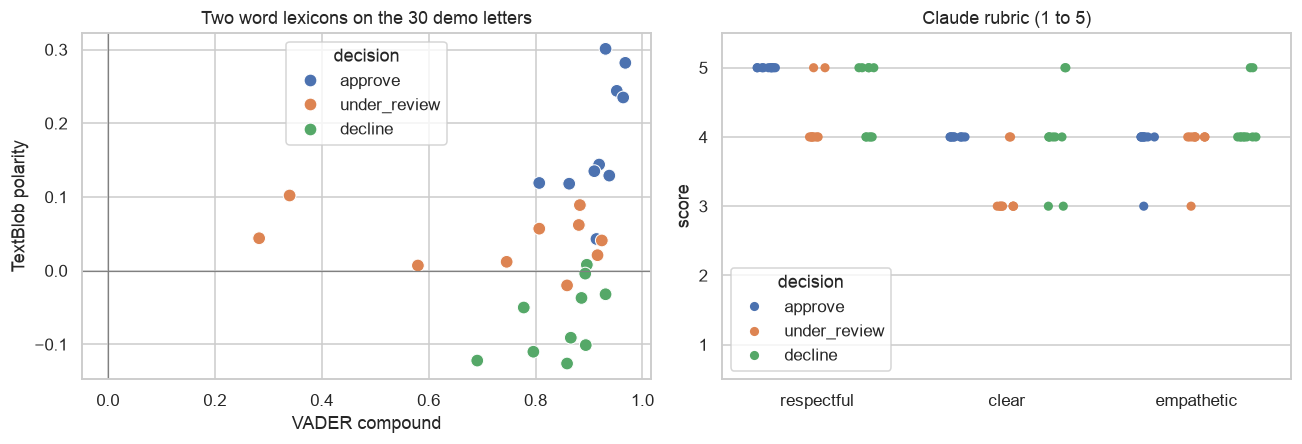

In [6]:
tone = summary[["vader", "tb_polarity", "tb_subjectivity", "respectful", "clear", "empathetic"]]
display(tone.describe().loc[["mean", "min", "max"]].round(2))
corr = tone.corr(method="spearman").round(2)
display(corr)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.scatterplot(data=summary, x="vader", y="tb_polarity", hue="decision", s=70, ax=axes[0])
axes[0].axvline(0, color="grey", lw=0.8); axes[0].axhline(0, color="grey", lw=0.8)
axes[0].set(title="Two word lexicons on the 30 demo letters", xlabel="VADER compound", ylabel="TextBlob polarity")
sns.stripplot(data=summary.melt(id_vars="decision", value_vars=["respectful", "clear", "empathetic"]),
              x="variable", y="value", hue="decision", dodge=True, jitter=0.15, s=6, ax=axes[1])
axes[1].set(title="Claude rubric (1 to 5)", xlabel=None, ylabel="score", ylim=(0.5, 5.5))
plt.tight_layout()
plt.savefig(FIGURES_DIR / "27_letter_tone.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
disagree = summary[(summary["tb_polarity"] < 0) & (summary["respectful"] >= 4)]
print(f"{len(disagree)} of {len(summary)} letters are negative on TextBlob but rated at least 4/5 respectful by Claude")
by = summary.groupby("decision")[["vader", "tb_polarity", "respectful"]].mean().round(2)
by

10 of 30 letters are negative on TextBlob but rated at least 4/5 respectful by Claude


,vader,tb_polarity,respectful
decision,,,
approve,0.92,0.18,5.0
decline,0.85,-0.07,4.5
under_review,0.72,0.04,4.2


**Why the lexicon methods struggle with formal letters**

- **They count words, not meaning.** VADER and TextBlob add up the sentiment of individual words. A decline letter is *about* bad news ("sorry", "cannot", "late payments", "low"), so a kind, respectful decline still scores negative, while an approval scores positive however it is worded. The lexicons mostly measure the *decision*, not the *tone*.
- **They were built for other text.** VADER was tuned on social media (emoticons, capitals, "!!!"); TextBlob's lexicon comes from product reviews. Neither knows that "a loan officer may be able to offer" is considerate.
- **The rude test letter shows it:** its blunt blaming scores barely below the polite letters on VADER, while the Claude rubric gives it 1/5.

So the lexicons are cheap, free and reproducible, useful as a sanity check (a strongly negative approval letter would be suspicious), but the **rubric is the score we show**, because it reads the letter the way an applicant would. The rubric itself is a model judgement, so a loan officer still reads every letter.

## 5. Save the audits for the app

In [8]:
out = ROOT / "app" / "demo_data" / "letter_audits.json"
out.write_text(json.dumps({k: a.to_dict() for k, a in audits.items()}, indent=1, ensure_ascii=False), encoding="utf-8")
print(f"Saved {len(audits)} audits to {out.relative_to(ROOT)} ({out.stat().st_size / 1e3:.0f} KB)")

Saved 30 audits to app/demo_data/letter_audits.json (59 KB)


## Takeaways

1. **The checker works before we trust it.** All four purpose-built bad letters are flagged for the right reason (invented "car you plan to buy", a strength described as a risk, 400,000 instead of 425,000, a rude letter) and the good control letter passes. The rude letter's claims are all true, so only the tone check catches it.
2. **The 30 demo letters are faithful.** 158 of 160 claims (98.8%) are supported by the fact sheet. One letter is flagged (#230043, an approval with invented reassurance), kept and shown with its flag so the officer edits it.
3. **The audit found a gap the rules missed** and led to a new guardrail: decline letters offered "a loan on different terms" when no path to approval existed. The new rule found seven such letters, which were redrafted.
4. **Coverage is partial by design.** Letters mention 77% of the top 3 risk factors for declines and 63% for under-review letters, because the prompt asks for the 2–3 most important factors in plain words and lets Claude skip ones an applicant would not understand.
5. **Tone: the lexicons measure the decision, not the tone.** Approvals score highest on VADER (0.92) and TextBlob (0.18), declines lowest on TextBlob (−0.07), while the Claude rubric rates every demo letter at least 4/5 respectful (mean 4.6) and at least 3/5 clear and empathetic. VADER and TextBlob only correlate 0.49 with each other and at most 0.28 with the rubric. We show the rubric in the app, with VADER and TextBlob as a cheap cross-check.
6. **Cost:** the audit adds about **$0.0004 per letter** (three or four Claude Haiku 5.5 calls) on top of about $0.0007 to draft it, so a checked letter costs about a tenth of a cent. Answers are cached, so re-running is free.

**Limits:** the matcher uses word overlap, so an unusual paraphrase can be misplaced (a false flag rather than a missed error), and the rubric is itself a model's judgement. The audit points the officer at sentences to check; it does not replace reading the letter.